# Módulo 8 — Transformada de Fourier
## Seção 8.8 — Amostragem, frequência de Nyquist e aliasing

**Objetivo de aprendizagem.** Entender como observações em instantes discretos representam oscilações contínuas; deduzir a ambiguidade de frequências (*aliasing*), relacionar taxa de amostragem e Nyquist, e distinguir aliasing de resolução da DFT e vazamento espectral.

**Pré-requisitos:** Seções 8.1–8.2 (frequência e período), 8.3 (Euler), 8.6–8.7 (DFT/FFT).

**Fonte principal consultada:** Morettin e Toloi (2018), v. 1, cap. 13, §13.2 e §13.4, pp. 335–350 (sinais harmônicos e frequências); cap. 14, §14.4.1, p. 367, eqs. (14.18)–(14.19) (frequências de Fourier $2\pi j/N$); cap. 14, §14.6, pp. 384–396 (filtragem e função de transferência). **Complementação didática:** o teorema ideal de amostragem e a prova específica de aliasing abaixo são apresentados como fundamentos complementares; não são atribuídos literalmente a essas seções.

---

### 1. O problema: medir uma onda em instantes discretos

Um sensor ou uma base de dados não conhece a função contínua $x(t)$ em todos os instantes. Ele registra valores

$$x_n=x(n\Delta t),\qquad n\in\mathbb Z,$$

onde $\Delta t>0$ é o intervalo de amostragem. Definimos:

$$\boxed{f_s=\frac1{\Delta t}}\quad \text{(amostras por unidade de tempo).}$$

Se $\Delta t=0{,}1$ segundo, $f_s=10$ amostras por segundo, ou $10$ hertz. Frequência física $f$ é expressa em ciclos/segundo (Hz); frequência discreta normalizada $\nu=f/f_s$ é expressa em ciclos/amostra; frequência angular discreta $\omega=2\pi\nu$ é expressa em radianos/amostra.

### 2. Amostragem de uma senoide e a ambiguidade de frequências

Considere o sinal contínuo

$$x(t)=A\cos(2\pi ft+\varphi).$$

As observações são

$$x_n=A\cos\left(2\pi\frac{f}{f_s}n+\varphi\right).$$

Para qualquer inteiro $m$, substitua $f$ por $f'=f+mf_s$. Obtemos

$$\begin{aligned}
A\cos\left(2\pi\frac{f'}{f_s}n+\varphi\right)
&=A\cos\left(2\pi\frac{f}{f_s}n+2\pi mn+\varphi\right)\\
&=A\cos\left(2\pi\frac{f}{f_s}n+\varphi\right),
\end{aligned}$$

pois $mn$ é inteiro. Logo,

$$\boxed{f\;\text{e}\;f+mf_s\;\text{são indistinguíveis após a amostragem uniforme}.}$$

Para senoides **reais**, também pode haver equivalência entre $f$ e $f_s-f$ com fases adequadas, devido à simetria do cosseno. A perda dessa distinção é o **aliasing**: frequências contínuas diferentes produzem a mesma sequência de amostras.

### 3. Exemplo numérico: 3 Hz e 7 Hz com 10 amostras/s

Tome $f_s=10$ Hz e duas funções $x_1(t)=\cos(2\pi\,3t)$ e $x_2(t)=\cos(2\pi\,7t)$. Nos tempos $t_n=n/10$:

$$\cos(2\pi\,7n/10)=\cos(2\pi n-2\pi\,3n/10)=\cos(2\pi\,3n/10).$$

Assim, 3 Hz e 7 Hz parecem idênticos quando observados apenas a cada 0,1 segundo — embora sejam ondas contínuas diferentes entre as amostras.

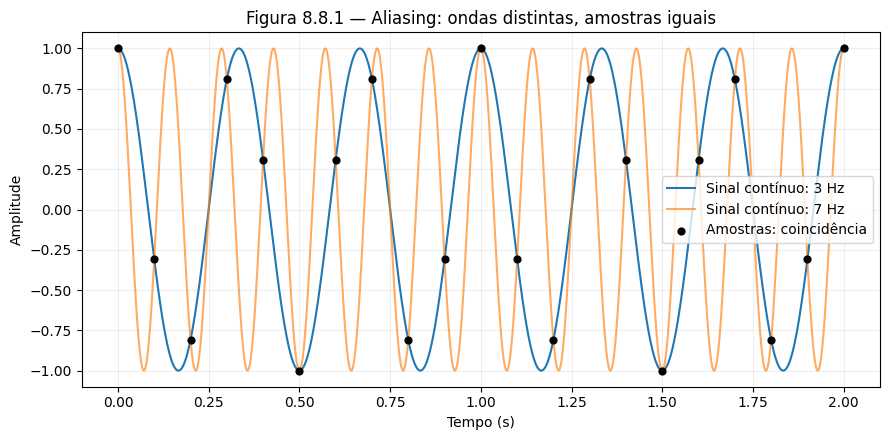

In [1]:
import numpy as np
import matplotlib.pyplot as plt
fs = 10.0
n = np.arange(21)
ts = n/fs
fine = np.linspace(0, 2, 2000)
x3 = np.cos(2*np.pi*3*ts)
x7 = np.cos(2*np.pi*7*ts)
assert np.allclose(x3, x7, atol=1e-12)
plt.figure(figsize=(9, 4.5))
plt.plot(fine, np.cos(2*np.pi*3*fine), label='Sinal contínuo: 3 Hz')
plt.plot(fine, np.cos(2*np.pi*7*fine), label='Sinal contínuo: 7 Hz', alpha=.65)
plt.scatter(ts, x3, color='black', s=24, zorder=3, label='Amostras: coincidência')
plt.xlabel('Tempo (s)'); plt.ylabel('Amplitude')
plt.title('Figura 8.8.1 — Aliasing: ondas distintas, amostras iguais')
plt.legend(); plt.grid(alpha=.2); plt.tight_layout(); plt.show()

**Interpretação da Figura 8.8.1:** as curvas contínuas não coincidem, mas todos os pontos de amostragem coincidem. Nenhum algoritmo posterior — mesmo uma FFT perfeitamente implementada — pode recuperar, só com esses pontos, qual das duas frequências foi originalmente medida.

### 4. Frequência de Nyquist e o teorema ideal de amostragem

A maior frequência positiva que pode ser representada **sem ambiguidade de sinal em amostragem real, sob hipóteses apropriadas**, é a frequência de Nyquist:

$$\boxed{f_N=\frac{f_s}{2}=\frac1{2\Delta t}.}$$

No exemplo anterior, $f_N=5$ Hz. Um sinal de 7 Hz aparece como 3 Hz, após o dobramento para a banda $[0,5]$ Hz.

O **teorema ideal de amostragem** (Shannon–Nyquist), em uma de suas formulações, afirma: se um sinal contínuo apropriado é estritamente limitado em banda a $|f|\leq B$ e $f_s>2B$, suas amostras uniformes infinitas determinam o sinal sob hipóteses de reconstrução ideal. Na prática, amostras finitas, ruído, filtros imperfeitos e a presença de energia acima de Nyquist limitam a recuperação. A igualdade no limite exige cuidado especial, pois componentes exatamente em Nyquist podem não ter fase identificável.

**Não confundir:** $f_N$ depende de $\Delta t$, enquanto a separação dos bins da DFT depende também do comprimento da janela.

### 5. Frequência discreta e grade de Fourier

Para $N$ observações tomadas a cada $\Delta t$, o comprimento da janela de $N$ pontos, pela convenção da DFT, é $T=N\Delta t$. A grade de frequências não negativas é

$$\boxed{f_k=\frac{k}{N\Delta t}=\frac{kf_s}{N}.}$$

A distância entre bins é $\Delta f=f_s/N=1/T$. Para $N$ par, o bin $k=N/2$ está em $f_s/2$; para $N$ ímpar, o último bin positivo fica abaixo de Nyquist. Maior $N$ com $f_s$ fixo fornece janela temporal maior e grade mais fina, mas não aumenta a frequência de Nyquist.

In [2]:
fs = 10.
for N in (20, 100):
    grid = np.fft.rfftfreq(N, d=1/fs)
    print(f'N={N:3d}: Nyquist={fs/2:.1f} Hz, passo={grid[1]-grid[0]:.2f} Hz, bins={len(grid)}')
    assert np.isclose(grid[-1], fs/2)  # N par

N= 20: Nyquist=5.0 Hz, passo=0.50 Hz, bins=11
N=100: Nyquist=5.0 Hz, passo=0.10 Hz, bins=51


### 6. Derivação da frequência aparente (dobramento)

Para uma senoide real com frequência física $f\geq0$, reduzimos primeiro a frequência módulo $f_s$:

$$r=f\bmod f_s,\qquad 0\le r<f_s.$$

Em seguida, pela simetria do cosseno, a frequência aparente na banda positiva é

$$\boxed{f_{\mathrm{alias}}=\min(r,\,f_s-r).}$$

Essa expressão descreve a *frequência não negativa aparente* de uma senoide real; **não preserva necessariamente a fase original**, e não substitui uma análise espectral completa de sinais complexos.

In [3]:
def frequencia_alias_real(f, fs):
    r = np.mod(f, fs)
    return np.minimum(r, fs-r)

fs = 10.
f_originais = np.array([1., 3., 5., 7., 12., 17.])
for f, fa in zip(f_originais, frequencia_alias_real(f_originais, fs)):
    print(f'{f:4.1f} Hz -> {fa:4.1f} Hz')
assert np.allclose(frequencia_alias_real(f_originais, fs), [1., 3., 5., 3., 2., 3.])

 1.0 Hz ->  1.0 Hz
 3.0 Hz ->  3.0 Hz
 5.0 Hz ->  5.0 Hz
 7.0 Hz ->  3.0 Hz
12.0 Hz ->  2.0 Hz
17.0 Hz ->  3.0 Hz


### 7. Aliasing, vazamento espectral e resolução: três fenômenos diferentes

**Aliasing** ocorre na amostragem: frequências diferentes tornam-se indistinguíveis. **Vazamento espectral** ocorre quando o recorte finito não contém um número inteiro de ciclos na grade da DFT: a energia de uma senoide distribui-se por diversos bins. **Resolução da grade** diz respeito ao espaçamento $1/(N\Delta t)$ entre frequências calculadas, que não garante por si só a distinção estatística de duas componentes em dados ruidosos.

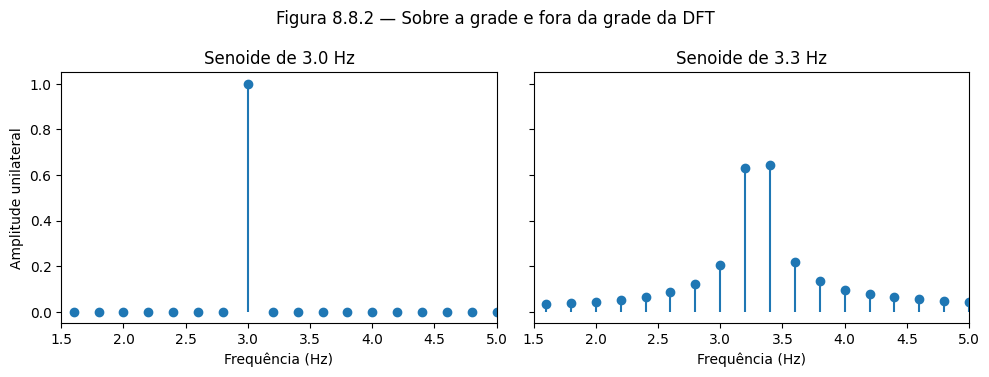

In [4]:
fs = 20.
N = 100
t = np.arange(N)/fs
freq = np.fft.rfftfreq(N, d=1/fs)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, f0 in zip(axs, [3.0, 3.3]):
    x = np.cos(2*np.pi*f0*t)
    amp = 2*np.abs(np.fft.rfft(x))/N
    amp[0] /= 2
    amp[-1] /= 2  # bin de Nyquist, N par
    ax.stem(freq, amp, basefmt=' ')
    ax.set_xlim(1.5, 5.0); ax.set_xlabel('Frequência (Hz)')
    ax.set_title(f'Senoide de {f0:.1f} Hz')
axs[0].set_ylabel('Amplitude unilateral')
fig.suptitle('Figura 8.8.2 — Sobre a grade e fora da grade da DFT')
plt.tight_layout(); plt.show()

**Interpretação da Figura 8.8.2:** 3,0 Hz coincide com um bin de frequência e concentra amplitude; 3,3 Hz não coincide com a grade (passo 0,2 Hz) e apresenta vazamento. **Nenhum dos dois sinais está acima de Nyquist (10 Hz); portanto, isso não é aliasing.**

### 8. Aplicação na análise de séries temporais

Em dados mensais, a taxa de amostragem é 1 amostra/mês, e Nyquist corresponde a 0,5 ciclo/mês — um período de **2 meses**. Uma sazonalidade anual tem frequência $1/12$ ciclo/mês e, portanto, está abaixo de Nyquist. Em dados diários, padrões intradiários não podem ser reconstruídos apenas com uma observação por dia, independentemente da quantidade total de anos registrados.

**Cuidados:** observações ausentes e tempos irregulares quebram as hipóteses da FFT uniformemente amostrada; o valor observado pode ser uma média ou agregado de um período, não uma amostra pontual de $x(t)$; filtros anti-aliasing devem atuar *antes* da redução da taxa de amostragem; ruído e dinâmica não estacionária modificam a interpretação dos espectros. Para modelos estatísticos de séries temporais, retome as hipóteses de estacionariedade do Módulo 1 e a ACF do Módulo 4.

### 9. Exercícios orientados

1. Uma série é amostrada a cada 15 minutos. Determine $f_s$, Nyquist e o período mais curto representável, usando unidades consistentes.
2. Demonstre a igualdade das amostras de 4 Hz e 6 Hz quando $f_s=10$ Hz e fase zero.
3. Faça o pseudocódigo de uma função que recebe $(f,f_s)$ e devolve a frequência alias positiva.
4. Repita a Figura 8.8.1 com $f_s=16$ Hz. As frequências 3 e 7 Hz continuam indistinguíveis? Justifique primeiro por álgebra.
5. Com $f_s=24$ observações/dia, compare $N=24$ e $N=240$ quanto a Nyquist e $\Delta f$. Explique por que são propriedades diferentes.
6. Analise: acrescentar zeros a uma amostra com $N=100$ pontos elimina aliasing, vazamento ou ambos? Justifique.

**Síntese.** A FFT organiza o cálculo da DFT, mas nenhum algoritmo pode reparar automaticamente a perda de informação causada pela amostragem inadequada. A frequência de Nyquist caracteriza o limite imposto pelo espaçamento temporal; o espaçamento entre bins caracteriza a janela observada.